In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
def get_pixels(r, i, mask_name, mask_vals):
    misr = r.obs['MISR']['sensor_list'][i]
    at3d = r.sensors_retrieval['MISR']['sensor_list'][i]
    mask = np.isin(r.masks['MISR']['sensor_list'][i][mask_name].data, mask_vals)
    x = misr.ray_x.data[mask]
    y = misr.ray_y.data[mask]
    m = misr.brf.data[mask]
    a = at3d.brf.data[mask]
    return misr, at3d, mask, x, y, m, a

In [29]:
"""
image_diff_grid.py

Creates a square grid figure where:
  - Row 0 / Col 0: raw images (diagonal)
  - Off-diagonal panels: tricontourf difference (image_i - image_j)

Usage:
    python image_diff_grid.py

Swap out the synthetic data in `make_sample_data()` with your own arrays.
Each dataset must share the same x, y coordinate arrays.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm

# # ── 1.  DATA  ────────────────────────────────────────────────────────────────

# def make_sample_data(n_images: int = 4, n_points: int = 500, seed: int = 0):
#     """
#     Returns x, y (shared coordinates) and a list of z arrays (one per image).
#     Replace this function with your own data loading logic.
#     """
#     rng = np.random.default_rng(seed)
#     x = rng.uniform(0, 1, n_points)
#     y = rng.uniform(0, 1, n_points)

#     labels = [f"Image {i+1}" for i in range(n_images)]
#     images = []
#     for i in range(n_images):
#         # Synthetic field: Gaussian bump shifted per image
#         cx, cy = 0.3 + 0.15 * i, 0.3 + 0.1 * i
#         z = np.exp(-((x - cx)**2 + (y - cy)**2) / 0.08) + rng.normal(0, 0.05, n_points)
#         images.append(z)

#     return x, y, images, labels


# ── 2.  PLOTTING  ─────────────────────────────────────────────────────────────
def plot_diff_grid(x, y, images, labels=None, n_levels: int = 15, cmap_raw="viridis", cmap_diff="RdBu_r",
                   raw_vlim=None, diff_vlim=None):
    """
    Parameters
    ----------
    x, y      : 1-D coordinate arrays shared by all images
    images    : list of N 1-D z arrays
    labels    : list of N strings (optional)
    n_levels  : number of contour levels
    cmap_raw  : colormap for raw images (diagonal)
    cmap_diff : colormap for difference panels (diverging recommended)
    raw_vlim  : (vmin, vmax) for raw panels. Defaults to data range across all images.
    diff_vlim : (vmin, vmax) for difference panels. Defaults to symmetric data range.
                vmin and vmax should typically be equal and opposite (e.g. (-1, 1)).
    """
    N = len(images)
    if labels is None:
        labels = [f"Image {i+1}" for i in range(N)]
 
    # Figure geometry
    fig = plt.figure(figsize=(3.2 * N, 3.0 * N))
    gs  = gridspec.GridSpec(N, N, figure=fig, hspace=0.13, wspace=0.05)
 
    axes = np.empty((N, N), dtype=object)
    for i in range(N):
        for j in range(N):
            axes[i, j] = fig.add_subplot(gs[i, j])
 
    # -- colour limits for raw data (shared scale)
    if raw_vlim is not None:
        raw_vmin, raw_vmax = raw_vlim
    else:
        raw_vmin = min(z.min() for z in images)
        raw_vmax = max(z.max() for z in images)
    raw_levels = np.linspace(raw_vmin, raw_vmax, n_levels)
 
    # -- colour limits for difference data (symmetric)
    if diff_vlim is not None:
        diff_vmin, diff_vmax = diff_vlim
    else:
        diff_abs_max = 0.0
        for i in range(N):
            for j in range(N):
                if i != j:
                    diff_abs_max = max(diff_abs_max, np.abs(images[i] - images[j]).max())
        diff_vmin, diff_vmax = -diff_abs_max, diff_abs_max
    diff_levels = np.linspace(diff_vmin, diff_vmax, n_levels)
    diff_norm   = TwoSlopeNorm(vmin=diff_vmin, vcenter=0, vmax=diff_vmax)
 
    # Collect handles for colorbars
    raw_handle  = None
    diff_handle = None
 
    for i in range(N):
        for j in range(N):
            ax = axes[i, j]
 
            if i == j:
                # ── Diagonal: raw image ──────────────────────────────────
                tcf = ax.tricontourf(x, y, images[i], levels=raw_levels,
                                     cmap=cmap_raw, vmin=raw_vmin, vmax=raw_vmax)
                if raw_handle is None:
                    raw_handle = tcf
                ax.set_title(labels[i], fontsize=9, fontweight="bold")
 
            else:
                # ── Off-diagonal: difference image_i − image_j ───────────
                diff = images[i] - images[j]
                tcf  = ax.tricontourf(x, y, diff, levels=diff_levels,
                                      cmap=cmap_diff, norm=diff_norm)
                if diff_handle is None:
                    diff_handle = tcf
                ax.set_title(f"{labels[i]} − {labels[j]}", fontsize=7.5)
 
            # Ticks only on outer edges
            ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
            if i < N - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xticks(ticks)
                ax.set_xticklabels(ticks, rotation=45)
            if j > 0:
                ax.set_yticklabels([])
            else:
                ax.set_yticks(ticks)
            ax.tick_params(labelsize=7)
 
    # ── Colorbars ─────────────────────────────────────────────────────────────
    # Raw colorbar on the right of the last column
    cb_raw_ax  = fig.add_axes([0.92, 0.55, 0.015, 0.35])
    cb_raw     = fig.colorbar(raw_handle, cax=cb_raw_ax)
    cb_raw.set_label("Value", fontsize=9)
    cb_raw.ax.tick_params(labelsize=7)
 
    # Diff colorbar below the figure
    cb_diff_ax = fig.add_axes([0.92, 0.10, 0.015, 0.35])
    cb_diff    = fig.colorbar(diff_handle, cax=cb_diff_ax)
    cb_diff.set_label("Difference", fontsize=9)
    cb_diff.ax.tick_params(labelsize=7)
 
    fig.suptitle("Image Comparison Grid  (diagonal = raw,  off-diagonal = difference)",
                 fontsize=11, y=1.01)
    return fig
 
# # ── 3.  MAIN  ─────────────────────────────────────────────────────────────────

# if __name__ == "__main__":
#     x, y, images, labels = make_sample_data(n_images=4)
#     fig = plot_diff_grid(x, y, images, labels)
#     out = "diff_grid.png"
#     fig.savefig(out, dpi=150, bbox_inches="tight")
#     print(f"Saved → {out}")
#     plt.show()

In [30]:
# mask_name = 'ray_containment'
# mask_vals = [1, 2]
# cam_i = 8
# misr, _, _, x, y, m, _ = get_pixels(list(exset.retrievals.values())[0], cam_i, mask_name, mask_vals)
# images = [m]
# labels = ['MISR']
# for r in list(exset.retrievals.values()):
#     _, _, _, _, _, _, a = get_pixels(r, cam_i, mask_name, mask_vals)
#     images.append(a)
#     labels.append(r.exp_name)

In [31]:
# sublabels = ['MISR', 'default', 'periodic', 'unconstrained', '0p150']

# index_map = {s: i for i, s in enumerate(labels)}
# indexes = [index_map[s] for s in sublabels]
# indexes

# subimages = [images[i] for i in indexes]

In [32]:
# for i, name in enumerate(exset.retrievals.keys()):
#     print(f'{i+1}: {name}')

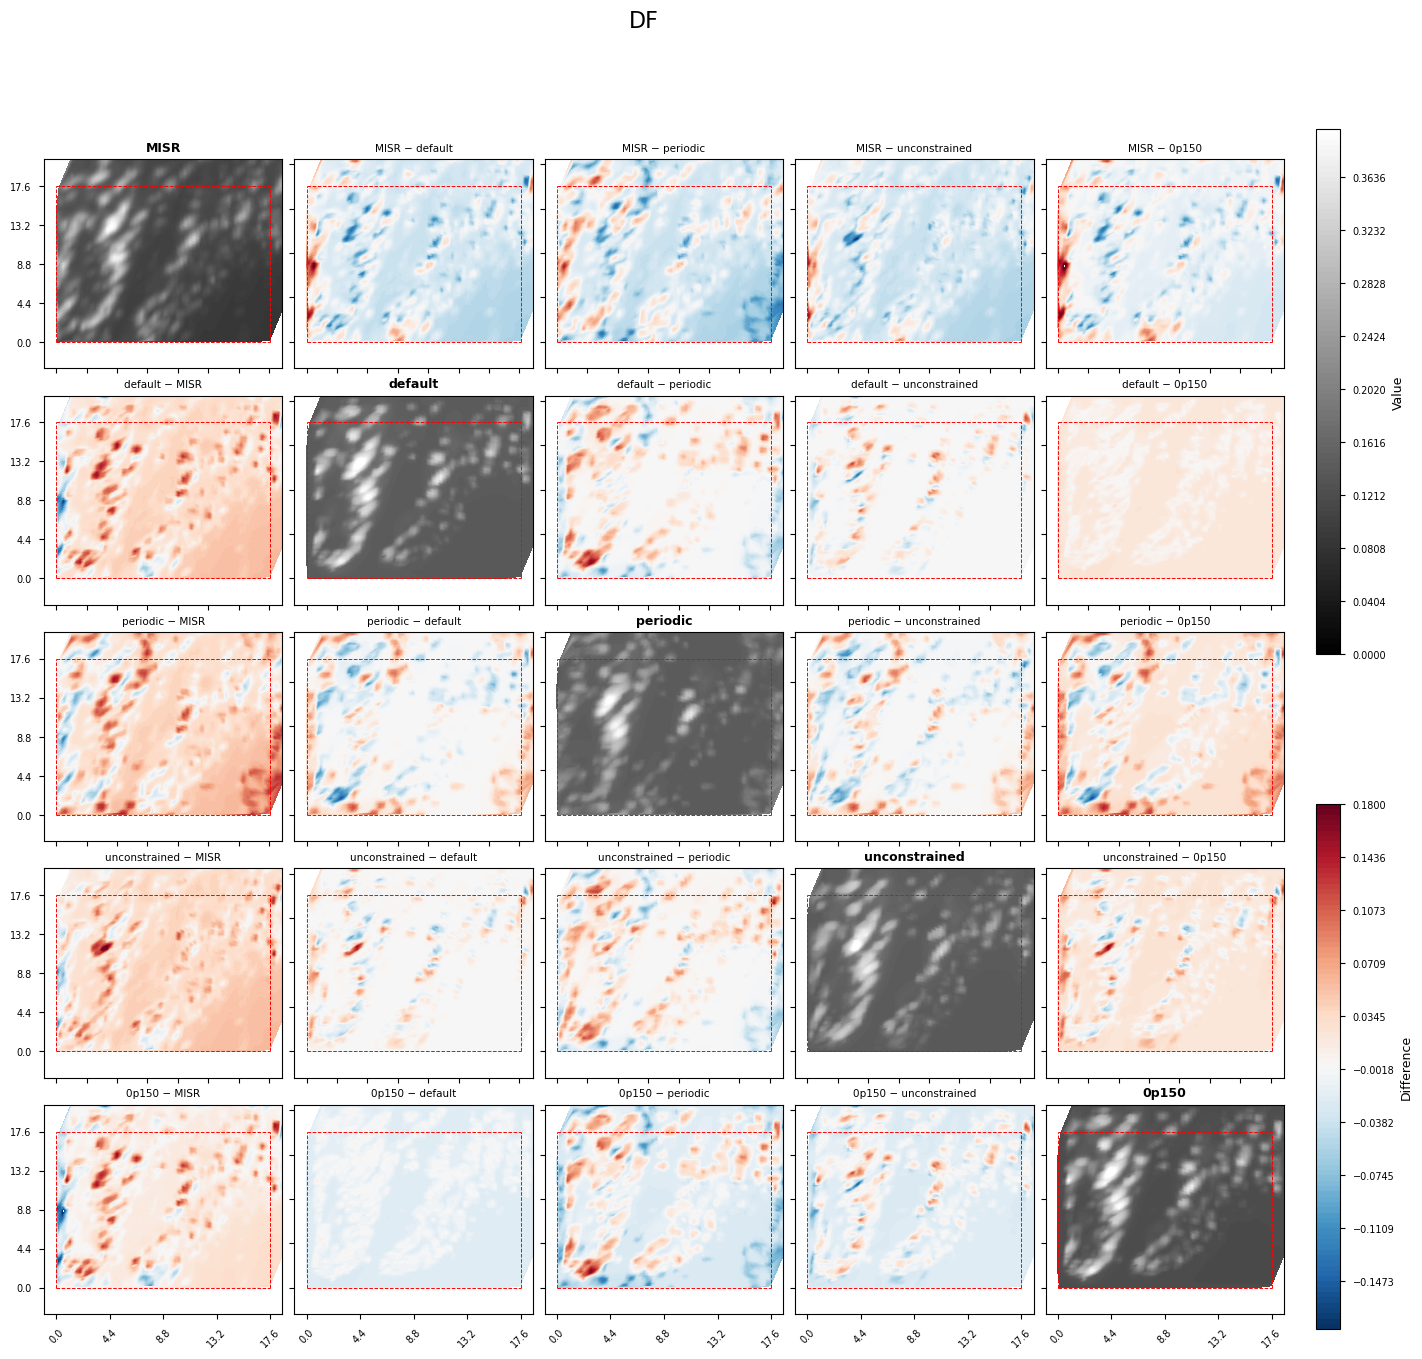

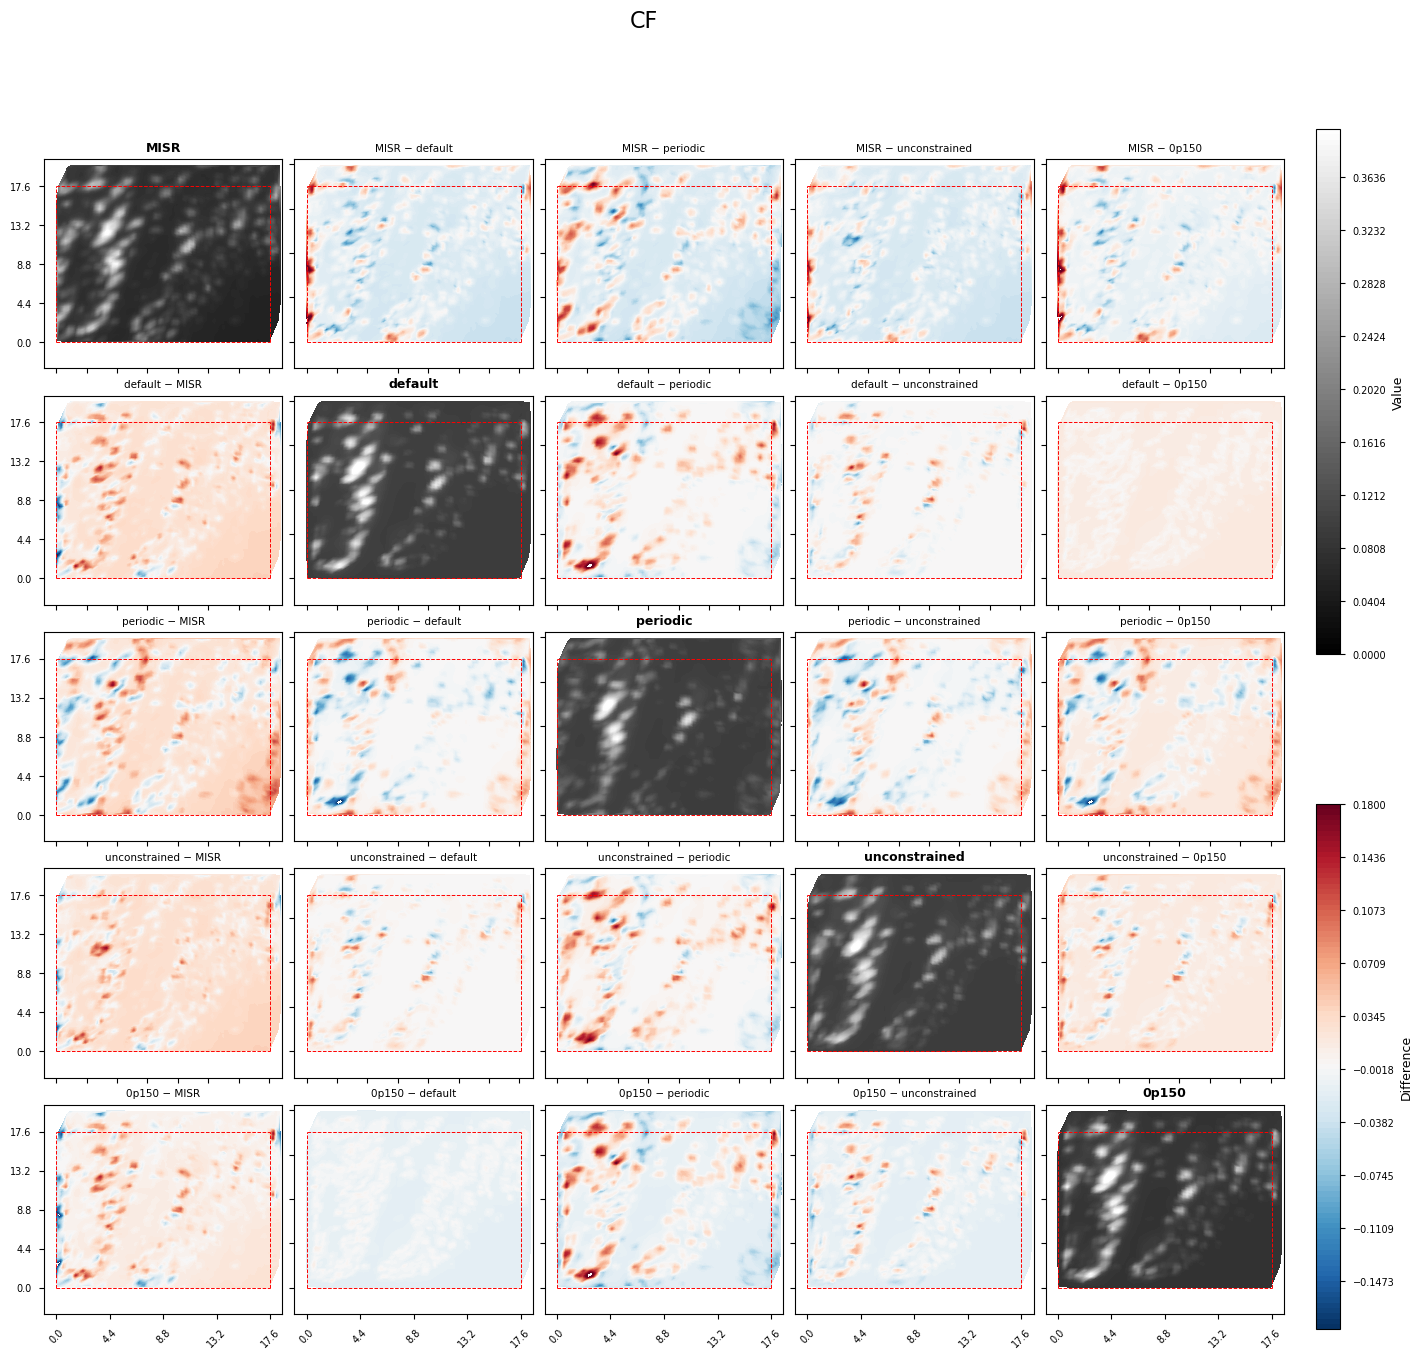

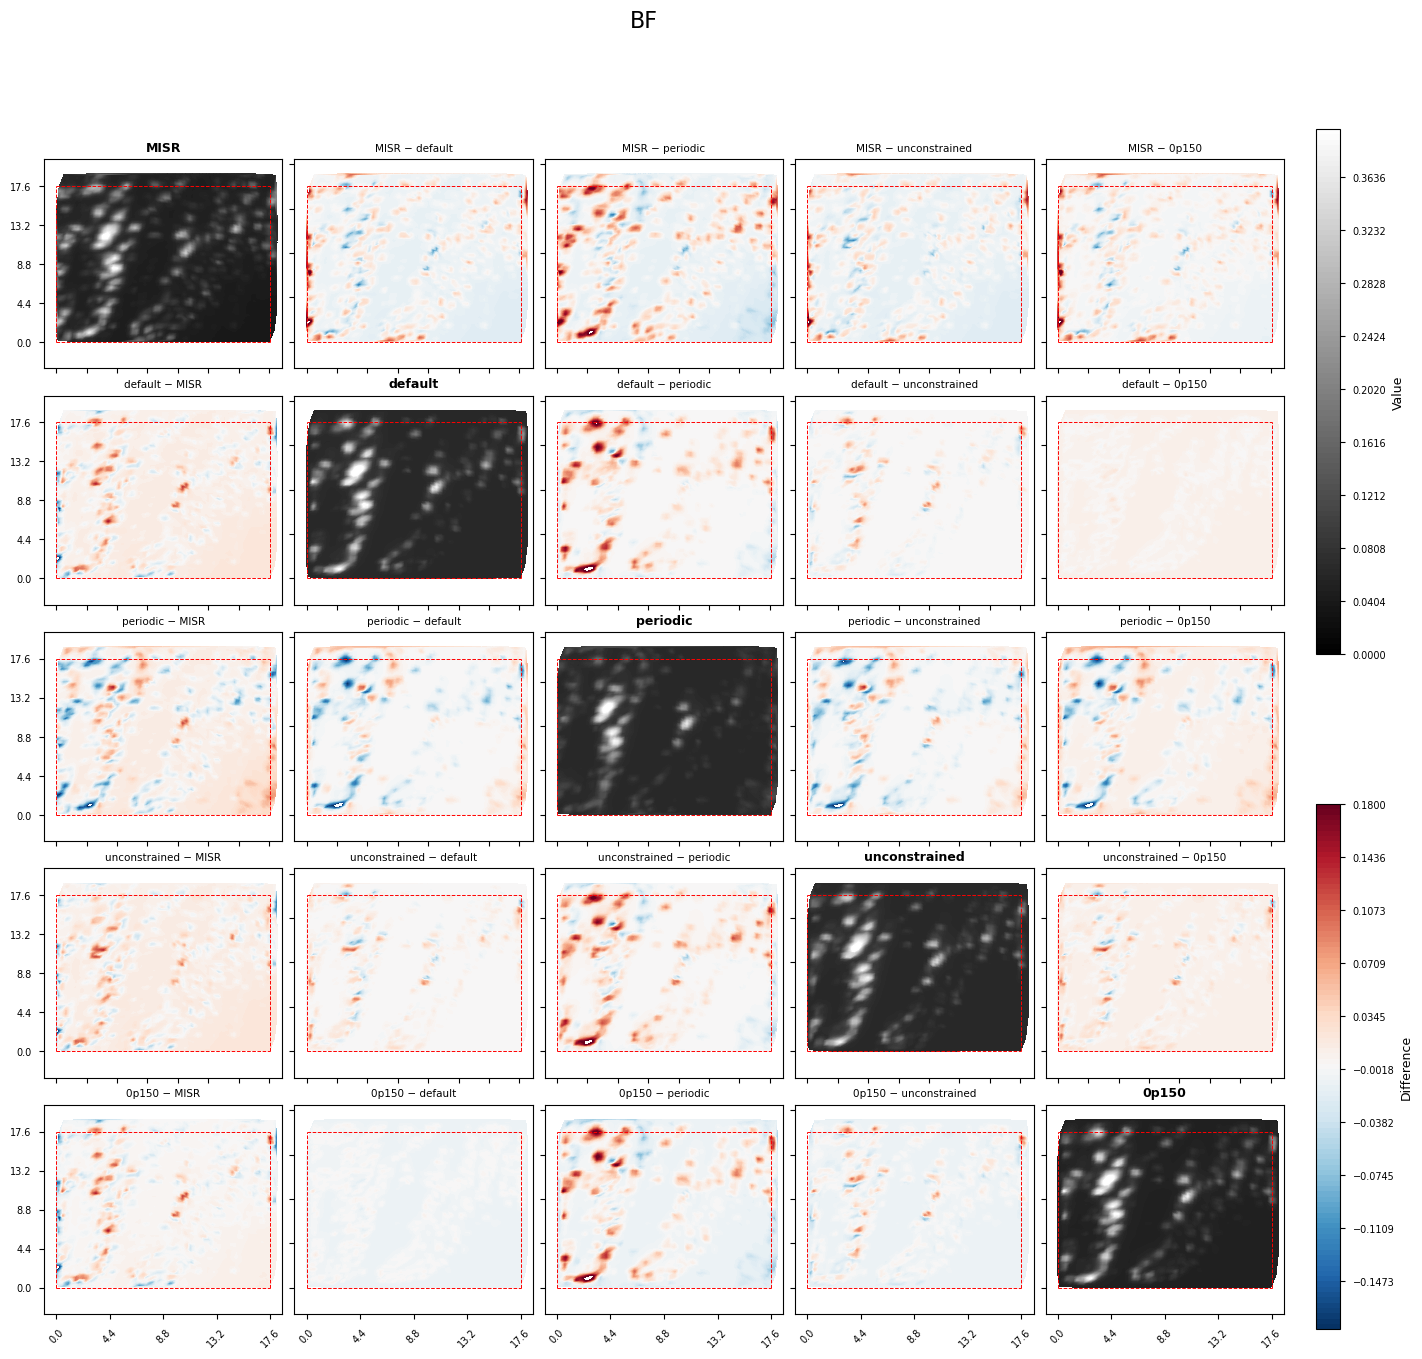

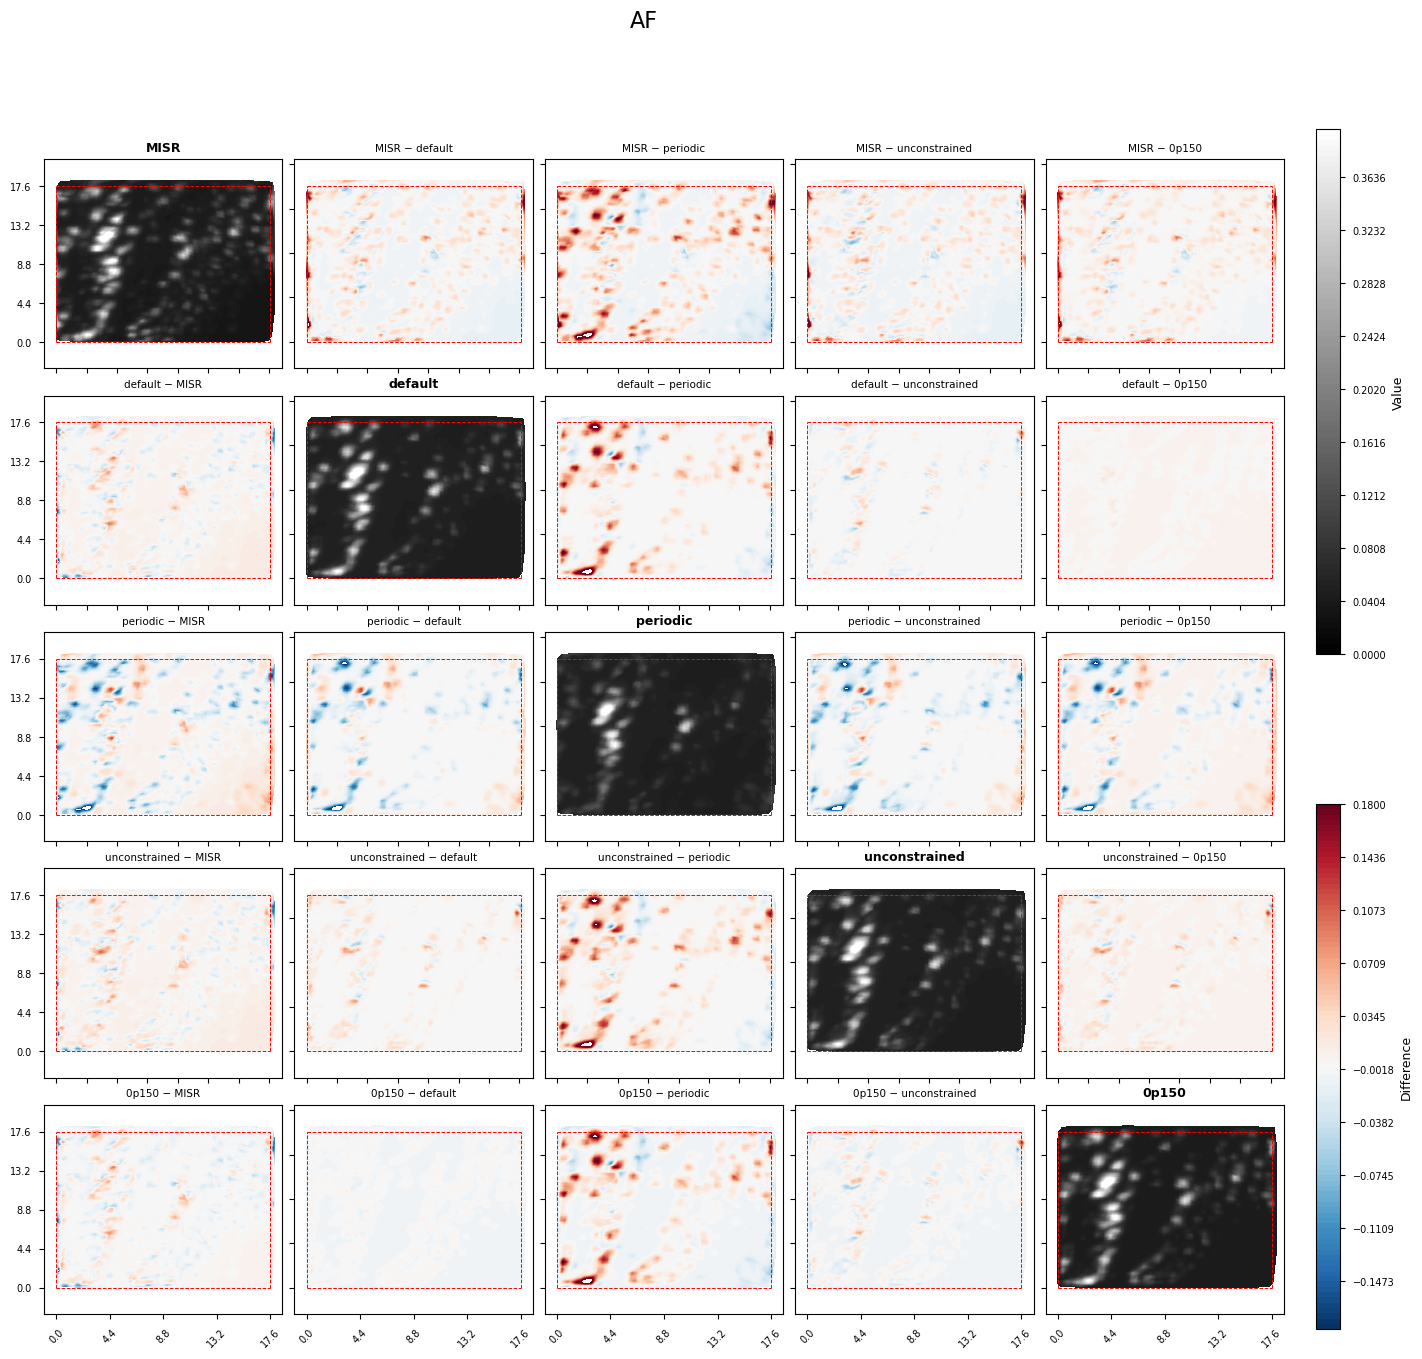

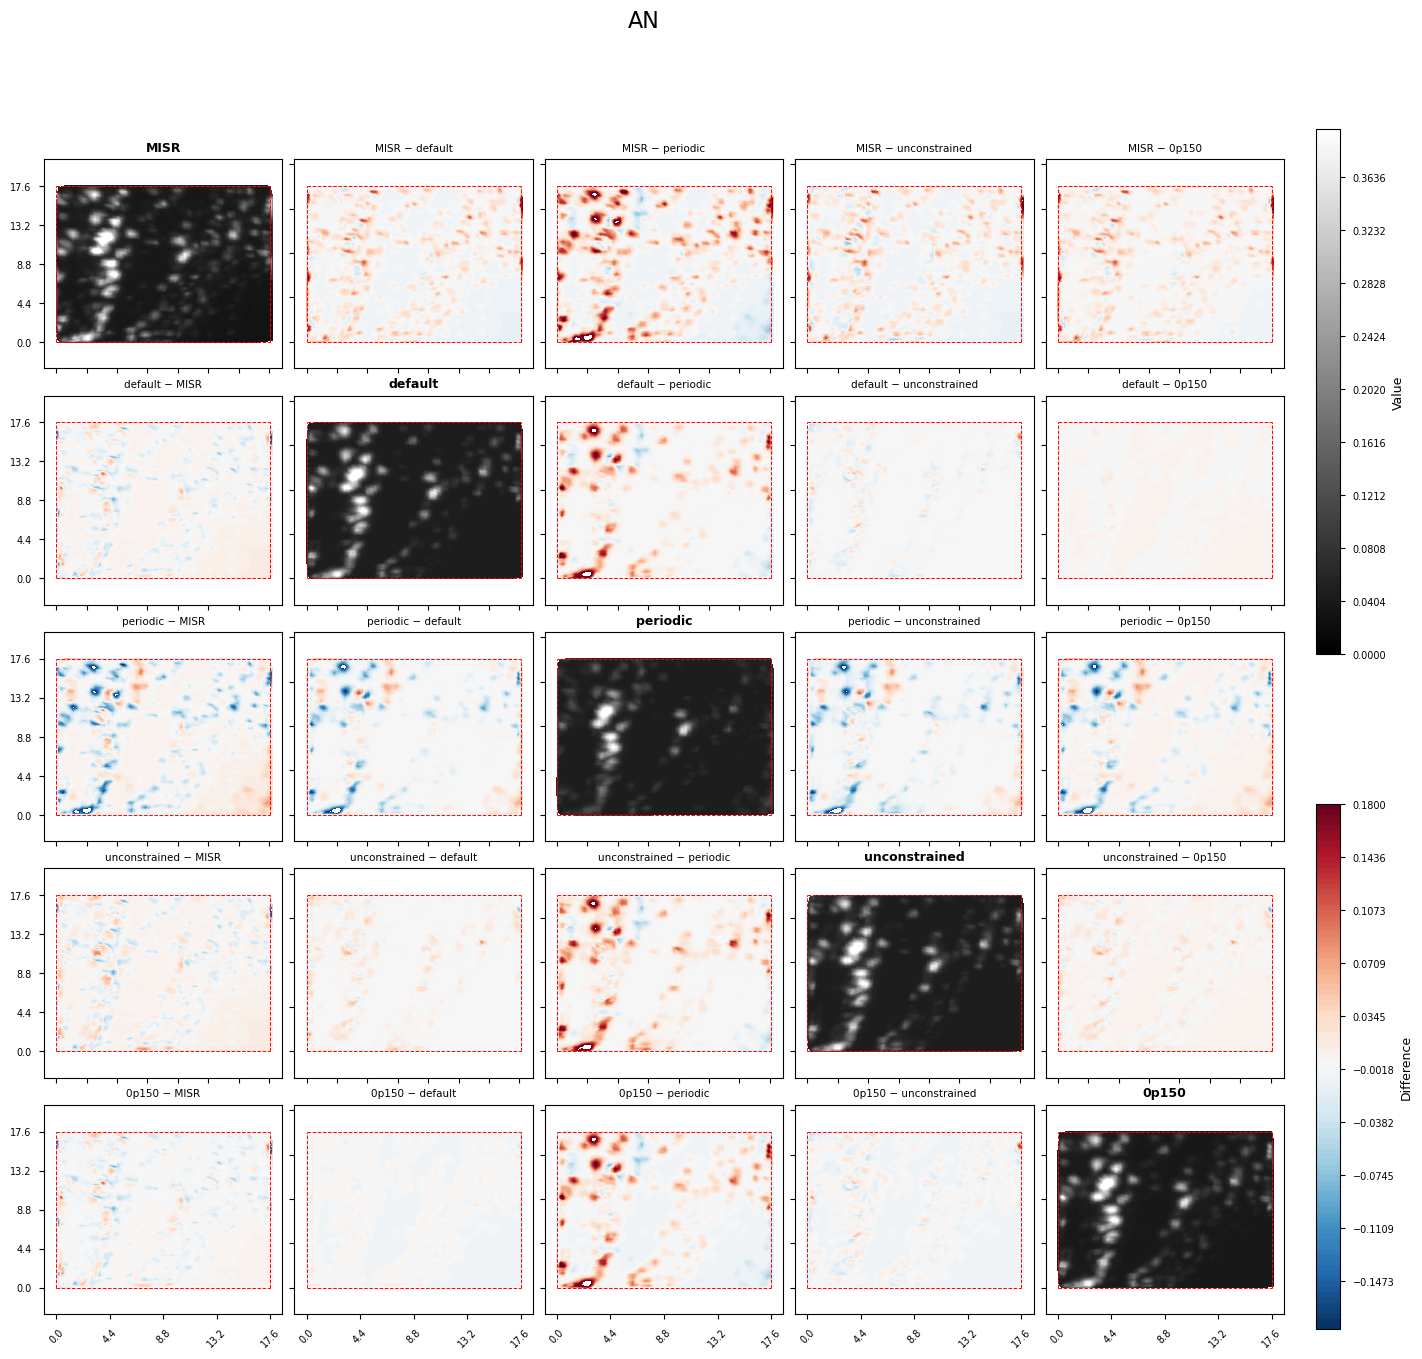

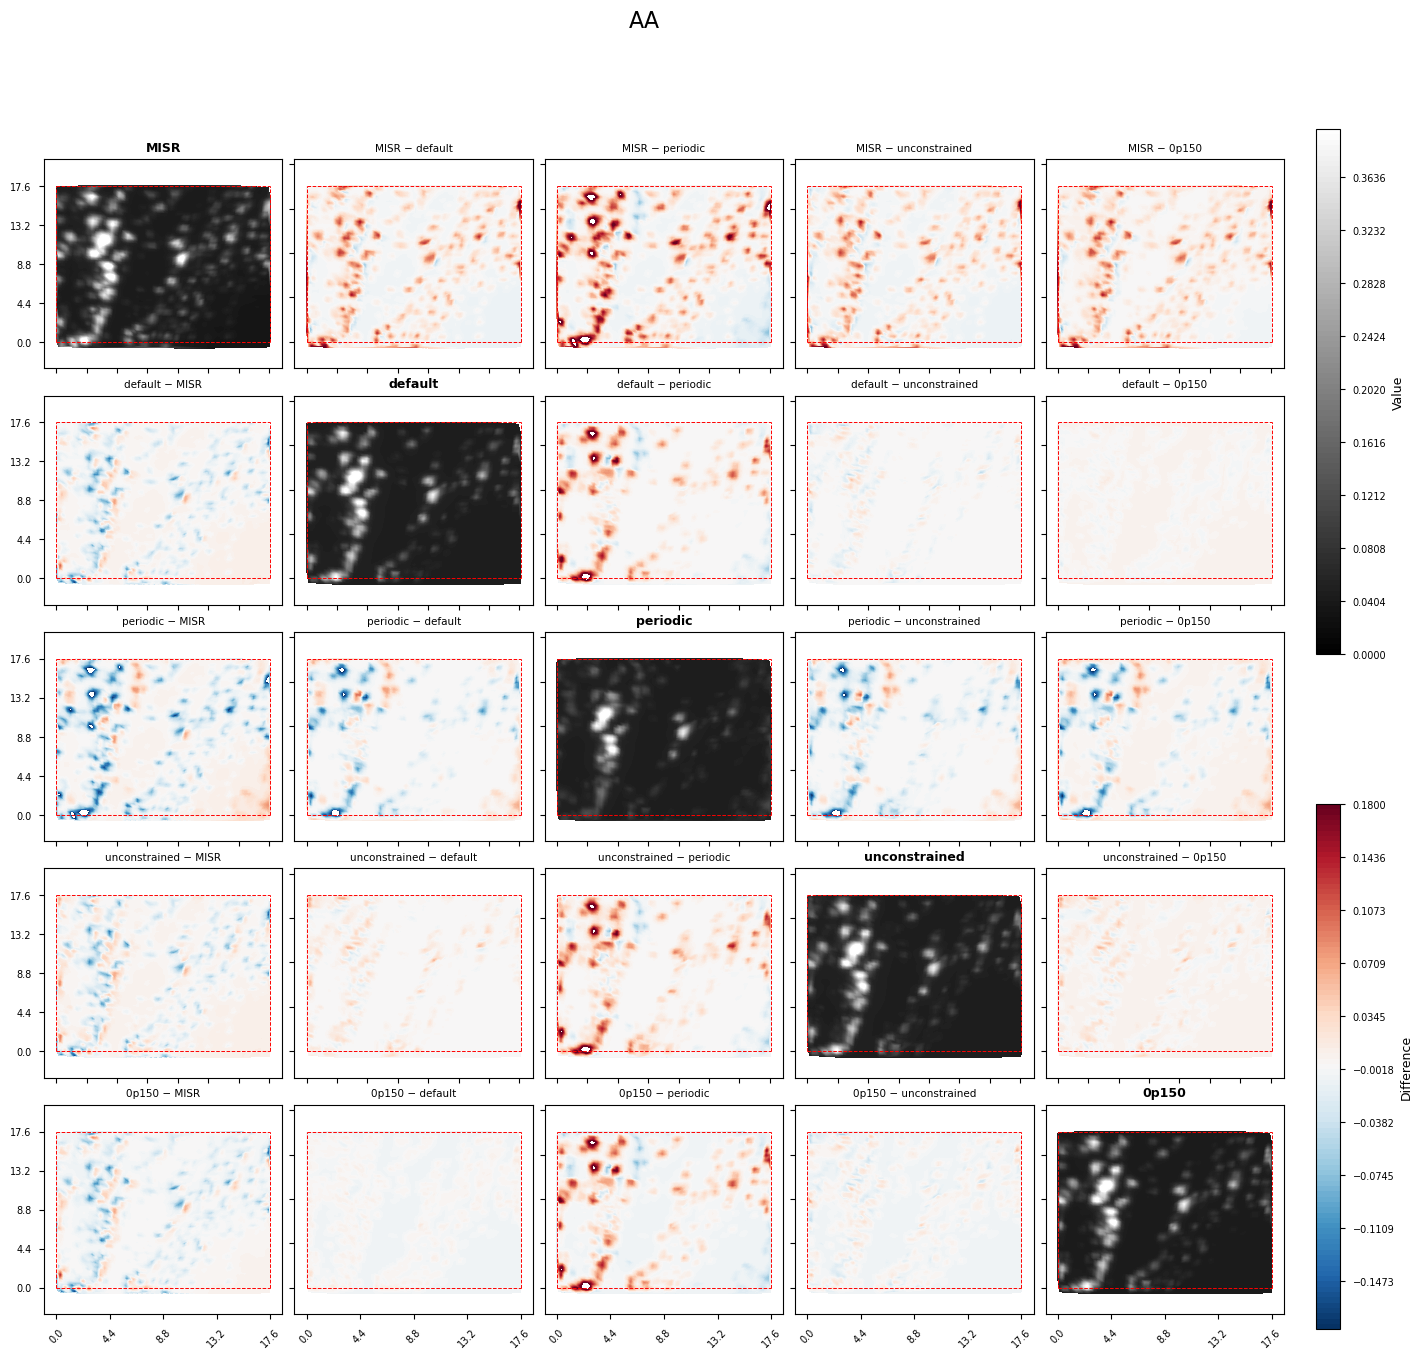

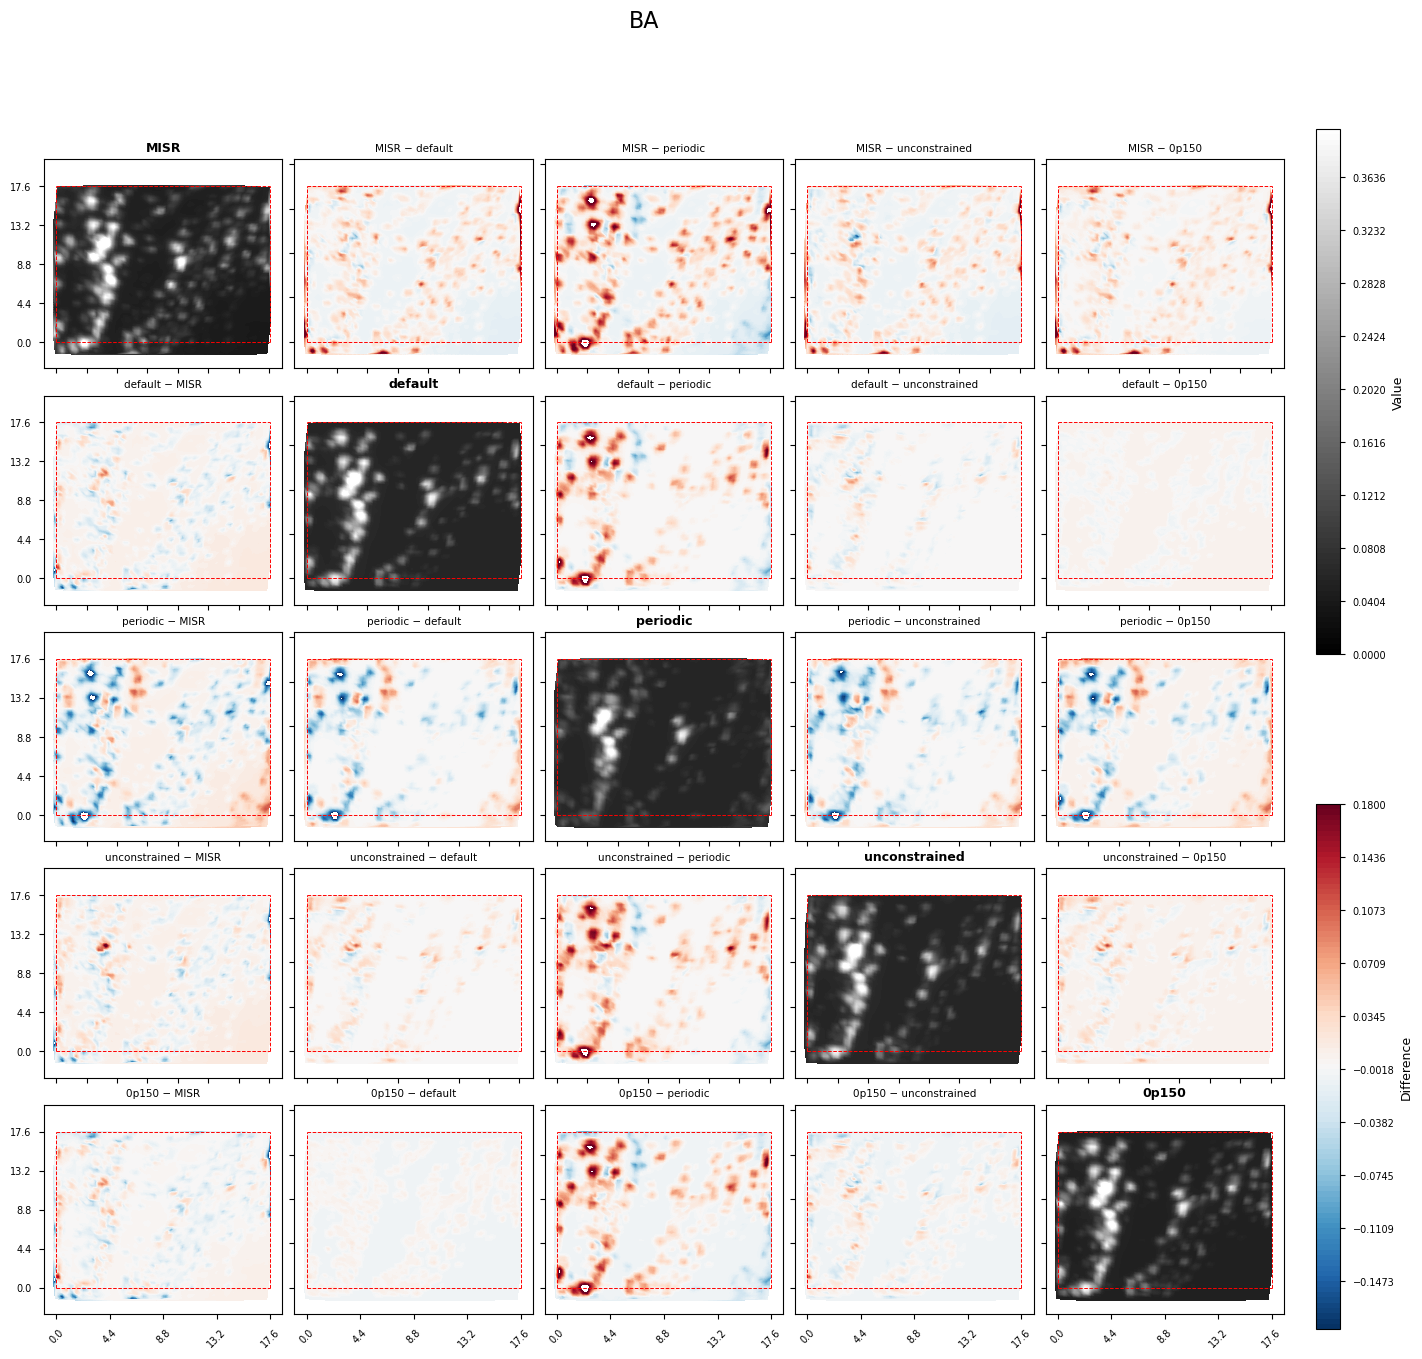

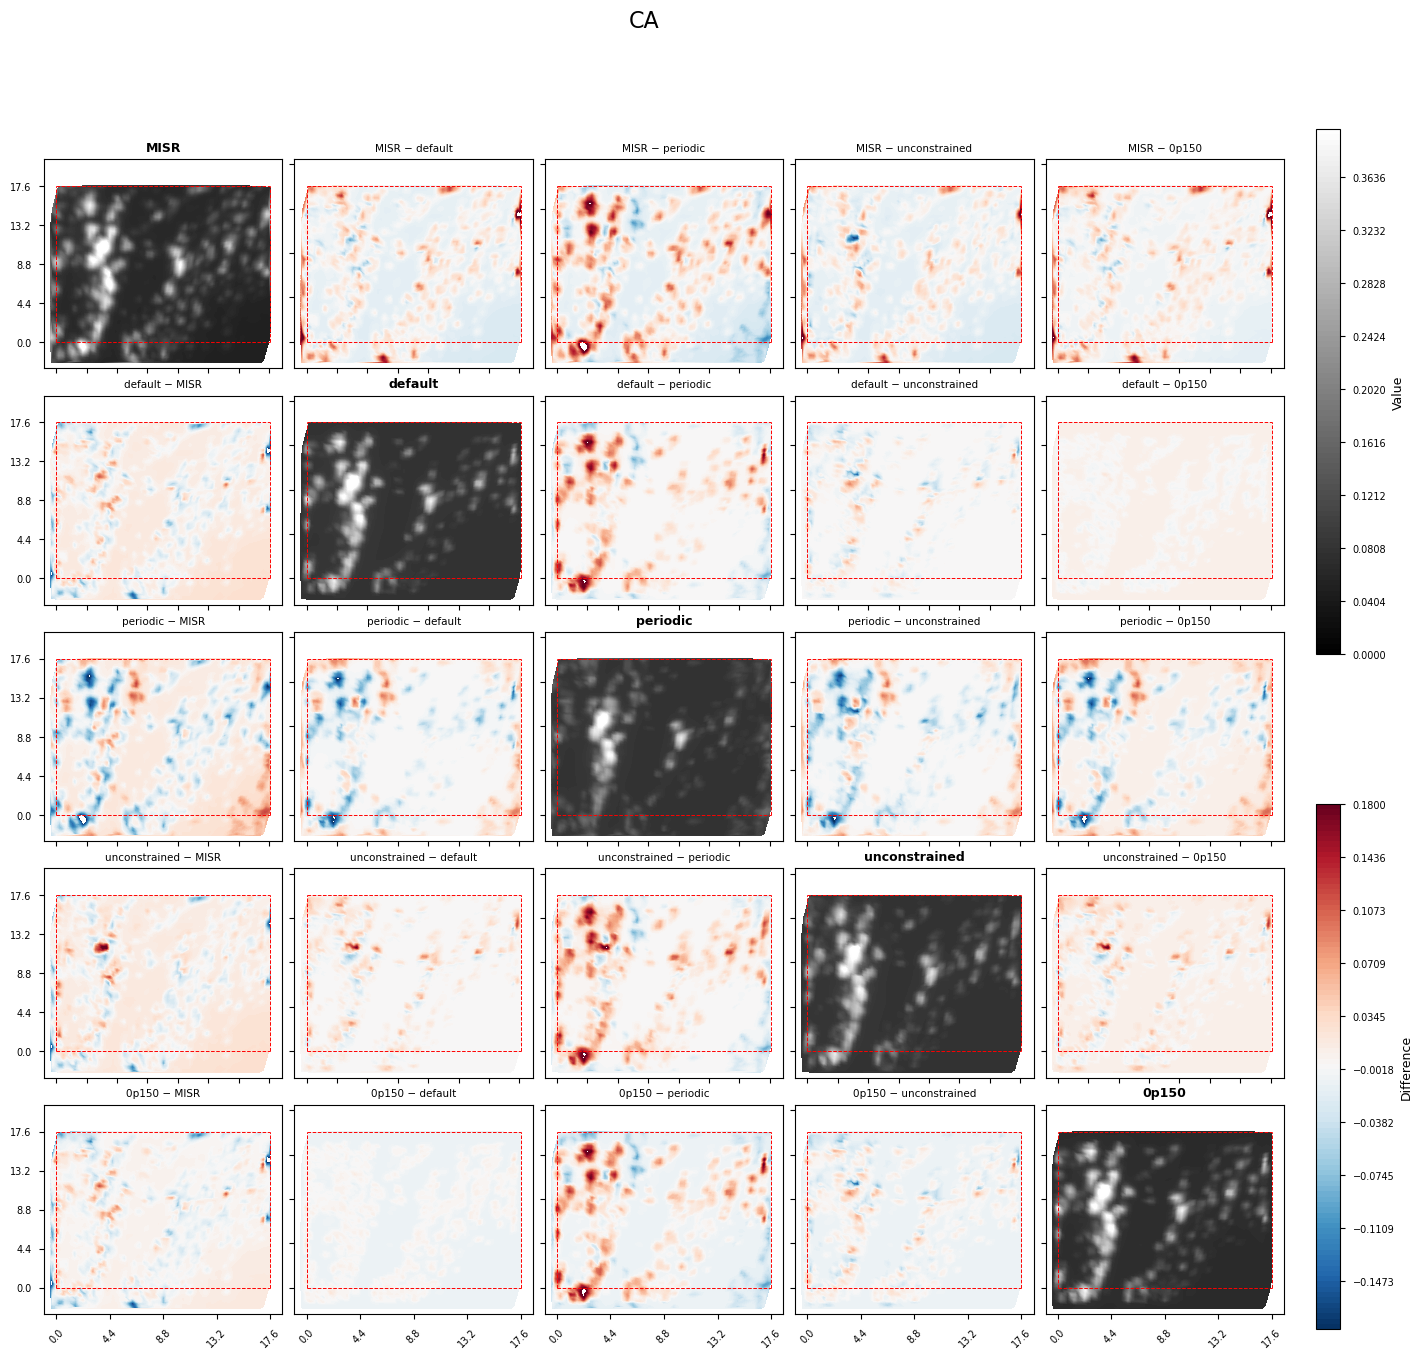

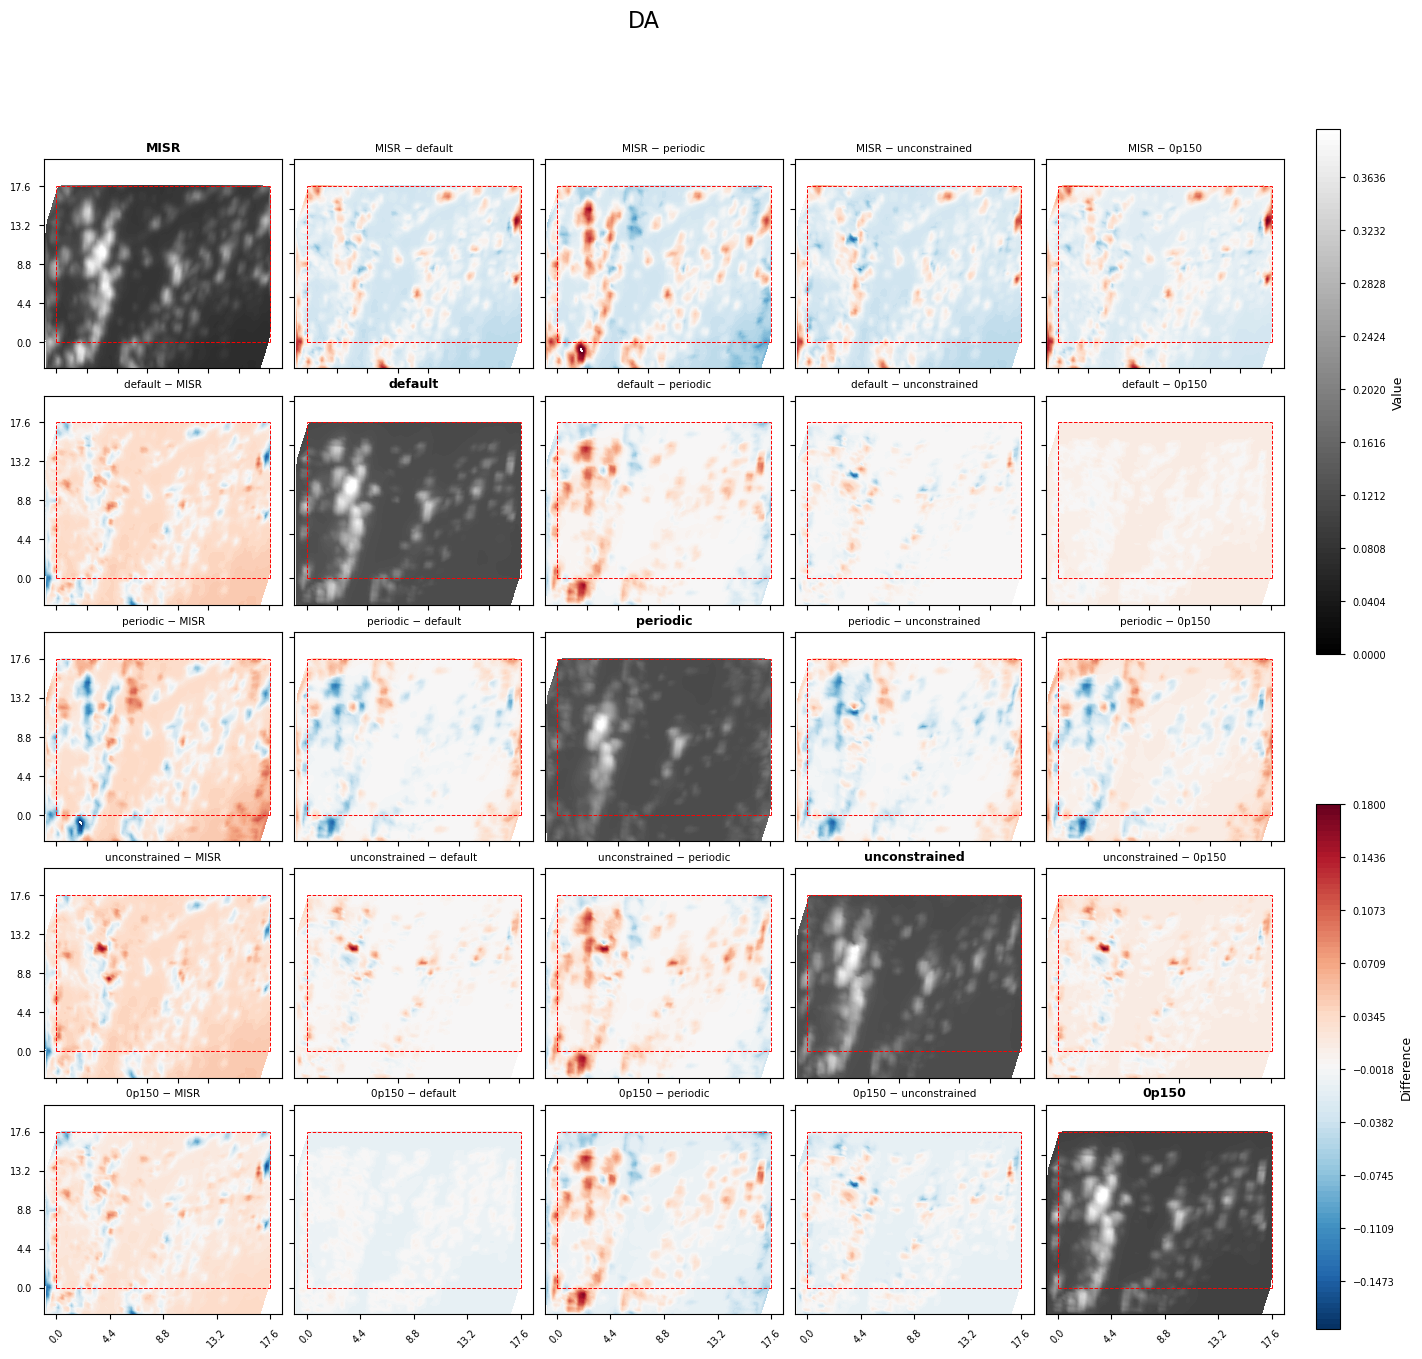

In [33]:
diff_vlim = (-0.18, 0.18)
for cam_i in range(9):
    mask_name = 'ray_containment'
    mask_vals = [1, 2]
    misr, _, _, x, y, m, _ = get_pixels(list(exset.retrievals.values())[0], cam_i, mask_name, mask_vals)
    images = [m]
    labels = ['MISR']
    for r in list(exset.retrievals.values()):
        _, _, _, _, _, _, a = get_pixels(r, cam_i, mask_name, mask_vals)
        images.append(a)
        labels.append(r.exp_name)

    sublabels = ['MISR', 'default', 'periodic', 'unconstrained', '0p150']
    # sublabels = ['MISR', '0p150', 'default', '0p250', 'mix22', 'mix54']
    index_map = {s: i for i, s in enumerate(labels)}
    indexes = [index_map[s] for s in sublabels]
    indexes
    subimages = [images[i] for i in indexes]

    fig = plot_diff_grid(x, y, subimages, labels=sublabels, n_levels=100, cmap_raw='gray', raw_vlim=(0, 0.4), diff_vlim=diff_vlim)
    fig.suptitle(misr.name, fontsize=16)
    ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
    box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
    for a in fig.axes[:-2]:
        a.plot([0, 0], [0, 17.6], **box_kwargs)
        a.plot([0, 17.6], [0, 0], **box_kwargs)
        a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
        a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
        # a.set_xticks(ticks)
        # a.set_xticklabels(ticks, rotation=45)
        # a.set_yticks(ticks)
        a.set_xlim([-1, 18.6])
        a.set_ylim([-3, 20.6])